# Races: runner levels when only the winner is seen

In many records only the **winner** and the **winning value** survive: the
winning time of a race, the winning bid of a tender, the first cause of a
failure. The other participants are known to have done worse, but by how much
is never observed. `FirstOrderStatistic` fits a model of every participant's
value from such data.

This notebook simulates races with a known truth, fits two models, and checks
what each recovers:

- **A**: runners independent given the course;
- **B**: plus a latent race-day factor (wind, heat) that moves all runners of a
  race together.

The functions used are those of [`docs/examples/race.py`](../examples/race.py);
the derivation of the likelihood and its exact derivatives is in
[`docs/first_order_statistic.md`](../first_order_statistic.md).

## 1. Theory

### Latent values

For race $t$ and runner $j$, the log time is

$$
v_{tj} = c_t + \mu_j + \sigma\,\varepsilon_{tj},
\qquad \varepsilon_{tj} \sim \mathcal N(0, 1),
$$

with $\mu_j$ the level of the runner (lower is faster), $\sigma$ the
race-to-race dispersion of a runner, and $c_t$ the conditions of the race:

| | $c_t$ | parameters |
|---|---|---|
| A | $x_t^\top\beta$ | $\mu, \log\sigma, \beta$ |
| B | $x_t^\top\beta + \tau u_t,\ u_t \sim \mathcal N(0,1)$ | $\mu, \log\sigma, \beta, \tau$ |

where $x_t$ holds an intercept and the elevation of the course.

### Likelihood of one race

Runner $w$ wins with time $v_t$ when its value is $v_t$ and every other entrant
$j \in P_t$ is slower. Given $c$, with $z_{tj}(c) = (v_t - c - \mu_j)/\sigma$:

$$
L_t(c) = \frac{1}{\sigma}\,\varphi\big(z_{tw}(c)\big) \prod_{j \in P_t \setminus w} \Phi\big(-z_{tj}(c)\big) .
$$

The losers enter only through survival probabilities: a runner who rarely wins
still informs the fit through every race it lost, and by how much it must have
been beaten.

### The race-day factor

In model B, $u_t$ is integrated out with Gauss–Hermite quadrature (nodes $u_k$,
weights $\omega_k$):

$$
\log L_t = \log \int L_t(x_t^\top\beta + \tau u)\,\varphi(u)\,du
\approx \operatorname{logsumexp}_k \Big(\log\omega_k + \log L_t(x_t^\top\beta + \tau u_k)\Big) .
$$

Model A is model B with $\tau = 0$. When a race-day factor exists and model A
ignores it, A has to explain the race-to-race swings of the winning time with
the runners alone: the runners look more erratic than they are (a larger
$\sigma$), and their levels are distorted with it.

### Identification

Adding a constant to every $\mu_j$ and subtracting it from the intercept
changes nothing, so $\sum_j \mu_j = 0$. The likelihood is symmetric in
$\tau$ (only $\tau^2$ matters), so $\tau = 0$ is a saddle point: model B starts
from model A's fit with $\sigma = \tau = \hat\sigma_A/\sqrt2$, which keeps $\tau$ away
from 0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, TEXT_2
import race as ex

ps.apply()

## 2. Simulated data

15 runners, 4,000 races: 3,000 to fit, 1,000 held out. Each runner enters a
random 20–50% of the races. The true race-day factor has $\tau = 0.06$ on the
log scale, more than the dispersion of a runner, $\sigma = 0.04$.

In [2]:
runners, wt, winner, entrants, X, truth = ex.simulate(tau=0.06, n_races=4000)
train, test = slice(0, 3000), slice(3000, None)
print("runners per race: %.1f on average" % entrants.sum(1).mean())
pd.Series(truth["mu"], index=runners).round(3).to_frame("true mu").T

runners per race: 5.4 on average


,R00,R01,R02,R03,R04,R05,R06,R07,R08,R09,R10,R11,R12,R13,R14
true mu,0.011,0.003,0.026,0.01,-0.009,0.018,0.046,0.035,-0.014,-0.031,-0.012,0.008,-0.063,0.0,-0.03


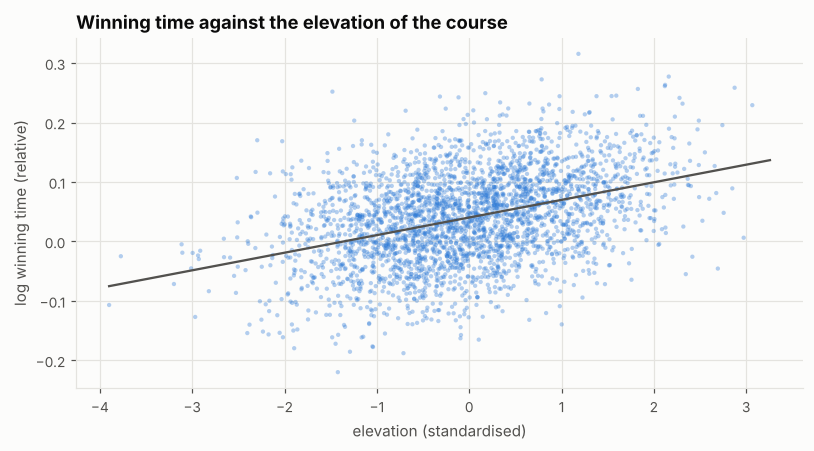

In [3]:
fig, ax = plt.subplots()
ax.scatter(X[train, 1], wt[train], s=8, color=BLUE, alpha=0.35, edgecolor="none")
b = np.polyfit(X[train, 1], wt[train], 1)
xx = np.linspace(X[:, 1].min(), X[:, 1].max(), 2)
ax.plot(xx, np.polyval(b, xx), color=TEXT_2, lw=1.5)
ps.finish(ax, "Winning time against the elevation of the course",
          "elevation (standardised)", "log winning time (relative)")

The elevation explains part of the winning time; the scatter around the line
is the race-day factor, the runners' own dispersion, and who happened to
enter.

## 3. Models and their graph

`FirstOrderStatistic` is a single node: it returns the log-likelihood of each
race, and `maxlike.LogLikelihood` adds them up.

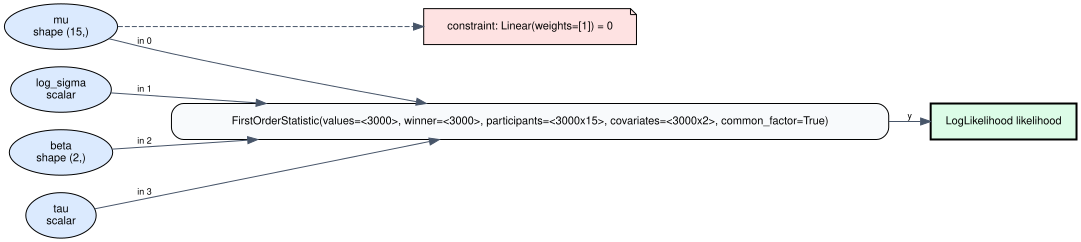

In [4]:
fits = {}
for cf, name in ((False, "A"), (True, "B")):
    fits[name] = ex.fit(runners, wt[train], winner[train], entrants[train], X[train], cf)
fits["B"].graph()

## 4. What each model recovers

**Runner levels.** Estimates against the truth, with 95% intervals.

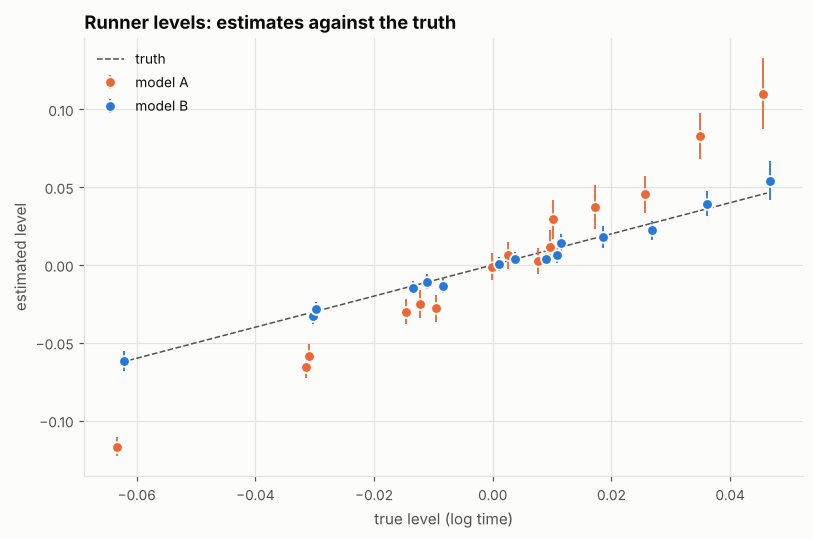

In [5]:
order = np.argsort(truth["mu"])
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(truth["mu"][order], truth["mu"][order], color=TEXT_2, lw=1, ls="--", label="truth")
for (name, mle), color, shift in zip(fits.items(), [ORANGE, BLUE], [-0.0006, 0.0006]):
    s = mle.summary().loc["mu"]
    ax.errorbar(truth["mu"][order] + shift, s["estimate"].values[order],
                yerr=1.96 * s["std_error"].values[order], fmt="o", color=color,
                markersize=7, elinewidth=1.2, markeredgecolor="#fcfcfb",
                markeredgewidth=1.2, label="model " + name)
ps.finish(ax, "Runner levels: estimates against the truth",
          "true level (log time)", "estimated level", legend=True)

In [6]:
rows = []
for name, mle in fits.items():
    s = mle.summary()
    est_mu = s.loc["mu", "estimate"].values
    se_mu = s.loc["mu", "std_error"].values
    row = {
        "mu RMSE": np.sqrt(np.mean((est_mu - truth["mu"]) ** 2)),
        "mu within 2 SE": np.mean(np.abs(est_mu - truth["mu"]) < 2 * se_mu),
        "sigma": np.exp(s.loc[("log_sigma", ""), "estimate"]),
        "beta intercept": s.loc[("beta", "intercept"), "estimate"],
        "beta elevation": s.loc[("beta", "elevation"), "estimate"],
        "tau": abs(s.loc[("tau", ""), "estimate"]) if name == "B" else np.nan,
    }
    rows.append(pd.Series(row, name="model " + name))
rows.append(pd.Series({"sigma": truth["sigma"], "beta intercept": truth["beta"][0],
                       "beta elevation": truth["beta"][1], "tau": truth["tau"]}, name="truth"))
pd.DataFrame(rows).round(4)

,mu RMSE,mu within 2 SE,sigma,beta intercept,beta elevation,tau
model A,0.0296,0.2667,0.0928,0.1793,0.0300,NaN
model B,0.0033,0.9333,0.0397,0.1023,0.0299,0.0602
truth,NaN,NaN,0.0400,0.1000,0.0300,0.0600


Both models put the runners in the right order, but model A **stretches**
the levels: its gaps between runners are about twice the true ones, and its
$\hat\sigma$ is more than twice the true dispersion. Its intervals are narrow
around the wrong values, so they cover the truth for only a quarter of the
runners. Model B recovers the levels, $\sigma$, the effect of elevation and
$\tau$, with intervals that cover the truth as they should.

## 5. Predictions: who wins?

The race-day factor shifts every runner of a race together, so it does not
change who wins; the dispersion $\sigma$ does. The win probability of each
entrant follows from $\mu$ and $\sigma$, here by simulation, and is checked on
the 1,000 held-out races.

model A: mean log-probability of the actual winner -1.2591


model B: mean log-probability of the actual winner -1.2467


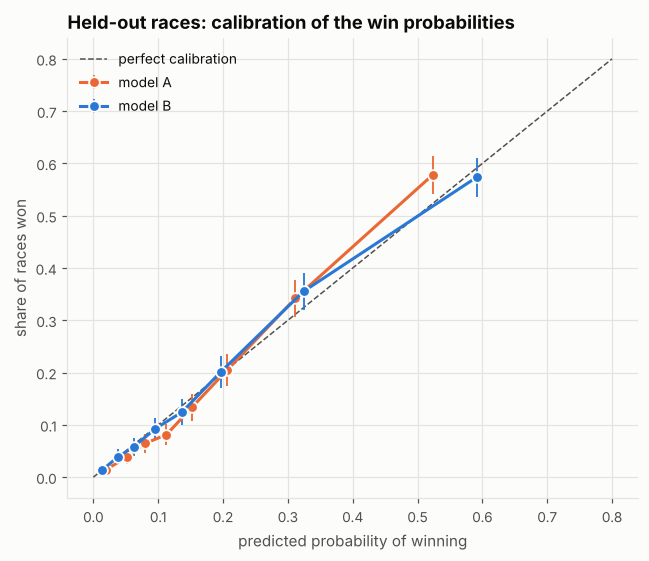

In [7]:
def win_probabilities(mle, entrants, draws=4000, seed=1):
    mu = np.ma.getdata(mle.get_params()[0])
    sigma = np.exp(float(np.ma.getdata(mle.get_params()[1])))
    rng = np.random.default_rng(seed)
    probs = np.zeros(entrants.shape)
    for t, row in enumerate(entrants):
        idx = np.flatnonzero(row)
        times = mu[idx] + sigma * rng.normal(size=(draws, idx.size))
        probs[t, idx] = np.bincount(times.argmin(1), minlength=idx.size) / draws
    return probs


e_test, w_test = entrants[test], winner[test]
won = np.zeros(e_test.shape)
won[np.arange(len(w_test)), w_test] = 1

fig, ax = plt.subplots(figsize=(6, 5.2))
ax.plot([0, 0.8], [0, 0.8], color=TEXT_2, lw=1, ls="--", label="perfect calibration")
for (name, mle), color in zip(fits.items(), [ORANGE, BLUE]):
    p = win_probabilities(mle, e_test)[e_test]
    hit = won[e_test]
    bins = pd.qcut(p, 8, duplicates="drop")
    g = pd.DataFrame({"p": p, "hit": hit}).groupby(bins, observed=True)
    mp, mh, n = g["p"].mean(), g["hit"].mean(), g["hit"].count()
    ax.errorbar(mp, mh, yerr=1.96 * np.sqrt(mh * (1 - mh) / n), fmt="o-", color=color,
                markersize=7, elinewidth=1.2, markeredgecolor="#fcfcfb",
                markeredgewidth=1.2, label="model " + name)
    print("model %s: mean log-probability of the actual winner %.4f" % (
        name, np.log(np.clip(p[hit == 1], 1e-6, None)).mean()))
ps.finish(ax, "Held-out races: calibration of the win probabilities",
          "predicted probability of winning", "share of races won", legend=True)

Who wins depends on the gaps between runners relative to $\sigma$. Model A
inflates both together, so its win probabilities end up close to model B's:
only its strongest favourites win a little more often than it predicts, and B
scores slightly better on the held-out winners. The gain from model B is
mostly in what the parameters mean (the levels, the dispersion, the size of
the race-day factor), not in picking winners.

## 6. When there is no race-day factor

On data simulated with $\tau = 0$, model B should find $\hat\tau \approx 0$ and
do no worse than A. The held-out log-likelihood per race (higher is better)
compares the two models on both data sets.

In [8]:
scores = {}
for tau in (0.06, 0.0):
    r, t_, w_, e_, X_, tr = ex.simulate(tau=tau, n_races=4000)
    for cf, name in ((False, "A"), (True, "B")):
        mle = fits[name] if tau == 0.06 else ex.fit(r, t_[train], w_[train], e_[train], X_[train], cf)
        scores[("tau = %.2f" % tau, "model " + name)] = ex.holdout_score(
            mle, t_[test], w_[test], e_[test], X_[test], cf)
        if tau == 0.0 and cf:
            print("data without a race-day factor: estimated tau %.4f +/- %.4f" % (
                abs(float(mle.get_params()[3])), float(mle.std_error()[3])))
table = pd.Series(scores).unstack()
table.round(4)

data without a race-day factor: estimated tau 0.0013 +/- 0.0148


,model A,model B
tau = 0.00,0.8225,0.8225
tau = 0.06,-0.0161,0.0516


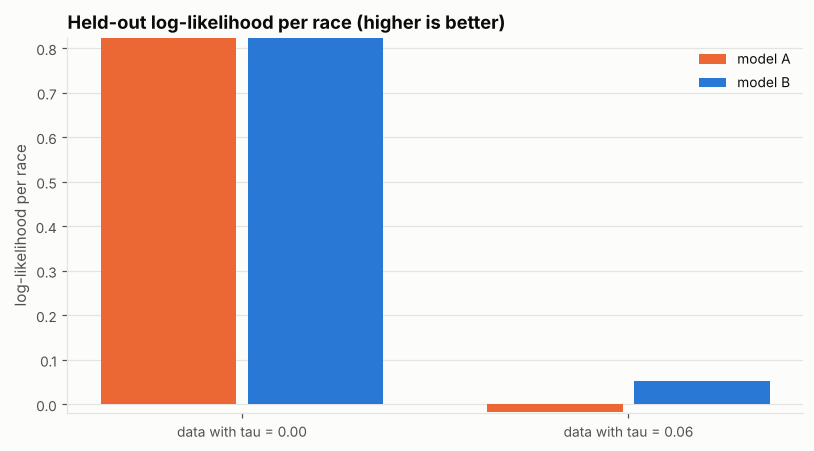

In [9]:
fig, ax = plt.subplots()
xx = np.arange(len(table.index))
w = 0.38
for k, (col, color) in enumerate(zip(table.columns, [ORANGE, BLUE])):
    ax.bar(xx + (k - 0.5) * w, table[col], w - 0.03, color=color, label=col)
ax.set_xticks(xx); ax.set_xticklabels(["data with " + i for i in table.index])
lo = table.values.min()
ax.set_ylim(lo - 0.15 * abs(lo), table.values.max() + 0.05 * abs(lo))
ax.grid(axis="x", visible=False)
ps.finish(ax, "Held-out log-likelihood per race (higher is better)", None,
          "log-likelihood per race", legend=True)

With a race-day factor, model B fits held-out races clearly better; without
one, it estimates $\tau$ near zero and matches model A. Model B is the safe
choice whenever the participants of an observation share conditions.